# Trabalho Prático - Notebook do grupo

**Inteligência Artificial - Graduação** · Prof. Bruno Nogueira · FACOM/UFMS · 2026/2

**Grupo:** CHATBOT RUMO · **Tema:** Chatbot sobre mobilidade acadêmica

---

Este é o notebook **entregável** do grupo. Ele precisa rodar do início ao fim
("Kernel → Restart & Run All") e **regerar os modelos** salvos em `modelos/`. A
estrutura segue o `00_exemplo_biblioteca.ipynb`; consulte-o sempre que tiver
dúvida.

Marcadores usados aqui:

* `🔨 TODO` - algo que o grupo precisa fazer/decidir;
* `📝 RELATÓRIO` - um resultado que deve aparecer (e ser discutido) no artigo.

Requisitos mínimos de cada seção estão no enunciado. Pode acrescentar seções,
células e análises à vontade - só não remova as seções numeradas.

---
## 0. Ambiente

In [1]:
import os
import subprocess
import sys
from pathlib import Path

# 🔨 TODO (só para o Colab): endereço do repositório do grupo
REPO_URL = "https://github.com/SEU_USUARIO/SEU_REPOSITORIO.git"

if "google.colab" in sys.modules:
    pasta = Path("/content") / Path(REPO_URL).stem
    if not pasta.exists():
        subprocess.run(["git", "clone", "-q", REPO_URL, str(pasta)], check=True)
    os.chdir(pasta)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"], check=True)

raiz = Path.cwd()
while not (raiz / "chatbot").is_dir():
    if raiz.parent == raiz:
        raise RuntimeError("Rode este notebook de dentro do repositório do trabalho.")
    raiz = raiz.parent
os.chdir(raiz)
sys.path.insert(0, str(raiz))

In [2]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, classification_report
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_predict, cross_validate
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier

from chatbot.avaliacao import avaliar, tabela_resumo
from chatbot.config import carregar_config
from chatbot.dados import adicionar_escopo, carregar_dados, resumo, validar_dados, vazamento
from chatbot.grafo import Conversa, construir_grafo
from chatbot.modelos import carregar_classificadores, salvar_classificadores
from chatbot.representacoes import tfidf_caracteres, tfidf_palavras
from chatbot.rotulos import CLASSES_ESCOPO

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
CORES = ["#4C72B0", "#DD8452", "#55A868", "#C44E52", "#8172B3"]
pd.set_option("display.max_colwidth", 80)

---
## 1. Configuração

🔨 TODO: preencha o `grupo.yaml` da raiz do repositório (tema e intenções
**validados com o professor**) antes de rodar esta seção.

In [3]:
config = carregar_config("grupo.yaml")
print("Grupo:", config.grupo, "| Tema:", config.tema)
pd.DataFrame([(i.nome, i.descricao) for i in config.intencoes.values()], columns=["intenção", "descrição"])

Grupo: chatbot RUMO | Tema: Chatbot de mobilidade acadêmica e intercâmbio da UFMS


,intenção,descrição
0,proficiencia,Exigência de idioma e certificados aceitos
1,custos_auxilio,"Custo do intercâmbio, bolsas e auxílios financeiros"
2,destino_parcerias,Universidades conveniadas e países disponíveis
3,mobilidade_nacional,Cursar um período em outra universidade brasileira
4,documentos_viagem,"Visto, passaporte, seguro saúde, vacinas e exigências de entrada em outros p..."
5,inscricao,"Editais abertos, prazos e formas de me candidatar"
6,requisitos,"Requisitos acadêmicos para participação (CRA, semestre, vínculo)"


---
## 2. Dados

O treino contém 1270 frases, 303 humanas e 967 geradas pela LLM utilizando o script disponibilizado. Das 1615 frases que geramos, por volta de 170 foram escolhidas para o treino após revisão. As frases humanas vieram de um formulário montado por nós que foi respondido por 44 pessoas. O teste tem 199 frases, todas humanas. Os negativos difíceis são sobre assuntos relacionados a UFMS.

📝 RELATÓRIO: tabela intenção × origem do treino e do teste.

In [4]:
treino = adicionar_escopo(carregar_dados(config.treino), config)
teste = adicionar_escopo(carregar_dados(config.teste), config)
print("Problemas no treino:", validar_dados(treino, config) or "nenhum")
print("Problemas no teste: ", validar_dados(teste, config) or "nenhum")
print("Vazamento treino→teste:", vazamento(treino, teste) or "nenhum")
display(resumo(treino))
display(resumo(teste))

Problemas no treino: nenhum
Problemas no teste:  nenhum
Vazamento treino→teste: nenhum


origem,humano,llm,total
intencao,,,
chitchat,10,140,150
custos_auxilio,21,99,120
destino_parcerias,40,80,120
documentos_viagem,21,99,120
fora_dominio,129,151,280
inscricao,44,76,120
mobilidade_nacional,7,113,120
proficiencia,5,115,120
requisitos,26,94,120


origem,humano,total
intencao,,
chitchat,34,34
custos_auxilio,18,18
destino_parcerias,18,18
documentos_viagem,18,18
fora_dominio,45,45
inscricao,18,18
mobilidade_nacional,15,15
proficiencia,15,15
requisitos,18,18


### Gerando frases de treino com o LLM (opcional)

Rode no terminal (ou descomente a célula abaixo). As frases vão para
`dados/gerados_llm.csv` e os prompts ficam registrados em `dados/prompts_llm.md`.
**Revise tudo** antes de copiar para o `treino.csv`; nunca use no teste; declare no
`USO_DE_IA.md`.

In [ ]:
# Para rodar daqui, tire o "#" das linhas abaixo (gasta créditos da chave do grupo):
# subprocess.run([sys.executable, "scripts/gerar_dados_llm.py", "--n", "10"], check=True)
# gerados = pd.read_csv("dados/gerados_llm.csv")
# gerados.sample(15)

Analise exploratória: No primeiro gráfico está mostrando a distribuição das frases pelos grupos, (domínio, chitchat, fora_dominio), sendo 840 pra domínio, 280 fora de domínio e 150 de chitchat, devido ao desbalanceamento das classes escolhemos a medida F1 Macro como métrica, que é a média do F1 Score de todas as classes. As 7 intenções tem 120 frases cada. As mensagens de chitchat são as mais curtas com média de 7.1 palavras. As frases que geramos por LLM são mais longas com média de 11.2 palavras que as humanas que tem 8.5 palavras, isso demonstra uma distinção de estilo em relação ao teste, que é formado 100% por frases humanas. As palavras mais frequentes de cada intenção são coerentes com o assunto em si.

🔨 TODO: análise exploratória - tamanho das mensagens por classe, palavras mais
frequentes por intenção, exemplos de negativos difíceis, diferenças entre frases
humanas e de LLM...

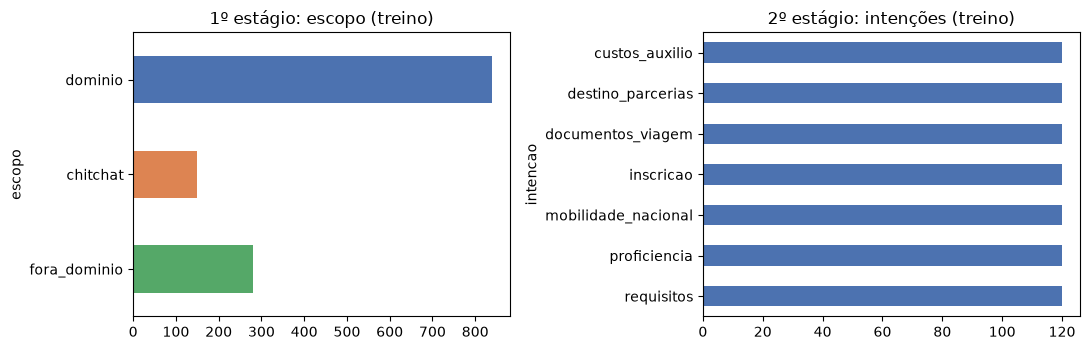

,mean,min,max
intencao,,,
chitchat,7.1,1,18
custos_auxilio,11.2,2,24
destino_parcerias,9.8,3,27
documentos_viagem,12.2,3,26
fora_dominio,9.8,2,30
inscricao,9.8,2,24
mobilidade_nacional,15.4,2,31
proficiencia,10.2,3,24
requisitos,11.3,2,24


,mean,min,max
origem,,,
humano,8.5,1,30
llm,11.2,1,31


chitchat             ['voce', 'foi', 'bom', 'ate', 'bot', 'estou', 'tudo', 'hoje']
custos_auxilio       ['intercambio', 'bolsa', 'auxilio', 'ufms', 'algum', 'despesas', 'quanto', 'financeiro']
destino_parcerias    ['ufms', 'universidades', 'paises', 'intercambio', 'conveniadas', 'instituicoes', 'fazer', 'convenio']
documentos_viagem    ['visto', 'preciso', 'pais', 'passaporte', 'intercambio', 'seguro', 'levar', 'antes']
fora_dominio         ['onde', 'faco', 'preciso', 'pais', 'por', 'curso', 'hoje', 'vida']
inscricao            ['edital', 'intercambio', 'processo', 'inscricao', 'onde', 'prazo', 'quando', 'candidatura']
mobilidade_nacional  ['outra', 'universidade', 'ufms', 'disciplinas', 'materias', 'destino', 'periodo', 'cursar']
proficiencia         ['certificado', 'proficiencia', 'idioma', 'ingles', 'comprovar', 'nivel', 'aceito', 'preciso']
requisitos           ['participar', 'intercambio', 'semestre', 'cra', 'preciso', 'estou', 'vinculo', 'disciplinas']


,texto,origem
92,Qual o valor da bolsa de iniciação científica?,humano
93,Posso me transferir para outro curso da UFMS?,humano
94,Como transfiro meu curso em definitivo para outra universidade,humano
95,Quais documentos são necessários para rematrícula,humano
114,qual cidades são ricas em recursos históricos,humano
121,para qual federal eu posso ir e que seja forte para meu curso?,humano
185,Qual área é responsável pelos estágios dentro da UFMS?,humano
195,como estagiar na ufms?,humano
214,qual universidade e referência no meu curso,humano
1120,Poderia explicar como funciona o processo de transferência entre cursos dent...,llm


In [5]:
from collections import Counter
from chatbot.texto import normalizar

# Distribuição das classes
fig, eixos = plt.subplots(1, 2, figsize=(11, 3.6))
treino["escopo"].value_counts().reindex(CLASSES_ESCOPO).plot.barh(ax=eixos[0], color=CORES[:3])
eixos[0].set_title("1º estágio: escopo (treino)"); eixos[0].invert_yaxis()
treino.loc[treino["escopo"] == "dominio", "intencao"].value_counts().plot.barh(ax=eixos[1], color=CORES[0])
eixos[1].set_title("2º estágio: intenções (treino)"); eixos[1].invert_yaxis()
plt.tight_layout(); plt.show()

# Tamanho das mensagens por classe e por origem
tam = treino.assign(n_palavras=treino["texto"].str.split().str.len())
display(tam.groupby("intencao")["n_palavras"].agg(["mean", "min", "max"]).round(1))
display(tam.groupby("origem")["n_palavras"].agg(["mean", "min", "max"]).round(1))

# Palavras mais frequentes por intenção
STOP = {"que", "como", "para", "pra", "com", "uma", "tem", "posso", "qual", "quais", "sobre", "minha", "meu", "nao", "sao", "ser", "mais"}
for intencao, g in treino.groupby("intencao"):
    c = Counter(p for t in g["texto"] for p in normalizar(t).split() if len(p) > 2 and p not in STOP)
    print(f"{intencao:20s}", [p for p, _ in c.most_common(8)])

# Exemplos de negativos difíceis (fora_dominio com palavras do tema)
fora = treino[treino["intencao"] == "fora_dominio"]
fora[fora["texto"].str.contains("bolsa|edital|inscri|ufms|curso|matr", case=False)][["texto", "origem"]].head(10)


---
## 3. Representações de texto

🔨 TODO: escolha **pelo menos duas** representações para comparar. Os construtores
de `chatbot/representacoes.py` aceitam os parâmetros do `TfidfVectorizer`
(`ngram_range`, `min_df`, `stop_words`, ...). Embeddings pré-treinados
(`EmbeddingsSentenca`) são opcionais.

In [7]:
from chatbot.texto import STOPWORDS, normalizar

REPRESENTACOES = {
    "TF-IDF palavras": tfidf_palavras,
    "TF-IDF caracteres": tfidf_caracteres,
    "TF-IDF palavras sem stopwords": lambda: tfidf_palavras(stop_words=STOPWORDS),
}


---
## 4. Classificador de escopo (dominio / chitchat / fora_dominio)

🔨 TODO: compare **pelo menos três algoritmos vistos em aula**, com validação
cruzada estratificada **só no treino**. Classificadores que ainda serão
apresentados na disciplina (KNN, Naive Bayes, SVM...) podem entrar quando forem
vistos.

📝 RELATÓRIO: tabela/gráfico da comparação, com média e desvio entre folds.

In [ ]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

CLASSIFICADORES = {
    "Regressão logística": lambda: LogisticRegression(C=10, max_iter=2000),
    "Rede neural (MLP)": lambda: MLPClassifier(hidden_layer_sizes=(64,), alpha=1e-3, max_iter=600,
                                               random_state=RANDOM_STATE),
    "Árvore de decisão": lambda: DecisionTreeClassifier(random_state=RANDOM_STATE),
    # 🔨 TODO: acrescente outros
}


def comparar(textos, rotulos):
    linhas = []
    for nome_rep, rep in REPRESENTACOES.items():
        for nome_clf, clf in CLASSIFICADORES.items():
            pipe = Pipeline([("vetorizador", rep()), ("classificador", clf())])
            r = cross_validate(pipe, textos, rotulos, cv=cv, scoring=["f1_macro", "accuracy"],
                               return_train_score=True, n_jobs=-1)
            linhas.append({"representação": nome_rep, "classificador": nome_clf,
                           "F1 macro (CV)": r["test_f1_macro"].mean(), "desvio": r["test_f1_macro"].std(),
                           "acurácia (CV)": r["test_accuracy"].mean(),
                           "F1 macro (treino)": r["train_f1_macro"].mean()})
    return pd.DataFrame(linhas).sort_values("F1 macro (CV)", ascending=False).reset_index(drop=True)


tab_escopo = comparar(treino["texto"], treino["escopo"])
tab_escopo.round(3)

🔨 TODO: ajuste de hiperparâmetros dos melhores candidatos (`GridSearchCV`), curva
de validação e escolha justificada do modelo final de escopo.

In [ ]:
# 🔨 TODO: substitua pelo pipeline e pela grade escolhidos pelo grupo
busca_escopo = GridSearchCV(
    Pipeline([("vetorizador", tfidf_caracteres()), ("classificador", LogisticRegression(max_iter=2000))]),
    param_grid={"classificador__C": [0.1, 1, 10, 100]},
    scoring="f1_macro", cv=cv, n_jobs=-1,
)
busca_escopo.fit(treino["texto"], treino["escopo"])
clf_escopo = busca_escopo.best_estimator_
print(busca_escopo.best_params_, round(busca_escopo.best_score_, 3))

📝 RELATÓRIO: matriz de confusão (validação cruzada), taxa de falso aceite e de
falsa recusa, e análise dos erros. Qual erro é mais grave **no seu domínio**?

In [ ]:
prev_cv = cross_val_predict(clf_escopo, treino["texto"], treino["escopo"], cv=cv)
ConfusionMatrixDisplay.from_predictions(treino["escopo"], prev_cv, labels=CLASSES_ESCOPO,
                                        cmap="Blues", colorbar=False)
plt.grid(False)
plt.show()
treino.assign(previsto=prev_cv).query("escopo != previsto")[["texto", "escopo", "previsto", "origem"]]

---
## 5. Classificador de tema (intenções do domínio)

🔨 TODO: mesma metodologia, treinando **só** com as mensagens do domínio.

In [ ]:
treino_dom = treino[treino["escopo"] == "dominio"]
tab_tema = comparar(treino_dom["texto"], treino_dom["intencao"])
tab_tema.round(3)

In [ ]:
# 🔨 TODO: ajuste de hiperparâmetros e escolha do modelo de tema
busca_tema = GridSearchCV(
    Pipeline([("vetorizador", tfidf_caracteres()), ("classificador", LogisticRegression(max_iter=2000))]),
    param_grid={"classificador__C": [0.1, 1, 10, 100]},
    scoring="f1_macro", cv=cv, n_jobs=-1,
)
busca_tema.fit(treino_dom["texto"], treino_dom["intencao"])
clf_tema = busca_tema.best_estimator_
print(busca_tema.best_params_, round(busca_tema.best_score_, 3))

In [ ]:
prev_tema = cross_val_predict(clf_tema, treino_dom["texto"], treino_dom["intencao"], cv=cv)
ConfusionMatrixDisplay.from_predictions(treino_dom["intencao"], prev_tema, labels=config.nomes_intencoes,
                                        cmap="Blues", colorbar=False, xticks_rotation=45)
plt.grid(False)
plt.show()
print(classification_report(treino_dom["intencao"], prev_tema, zero_division=0))

---
## 6. Limiar de confiança

🔨 TODO: escolha `roteamento.limiar_tema` (no `grupo.yaml`) com base nas
probabilidades da validação cruzada, como na seção 9 do exemplo. Justifique.

In [ ]:
# 🔨 TODO

---
## 7. Salvar os modelos finais

In [ ]:
salvar_classificadores(clf_escopo, clf_tema, config)
config = carregar_config("grupo.yaml")  # relê, caso o limiar tenha sido alterado

---
## 8. O chatbot funcionando (com o LLM do OpenRouter)

🔨 TODO: reúna os documentos em `documentos/` (uma subpasta por intenção + `geral/`,
com o `FONTES.md`), ajuste `persona` e `contato` no `grupo.yaml` e mostre conversas
que ilustrem acertos **e** limitações do bot (inclusive perguntas cuja resposta
não está nos documentos). Se o grupo alterou o grafo (`chatbot/grafo.py`),
explique aqui o que mudou.

Antes: configure a chave no `.env` (ou nos *Secrets* do Colab) e rode
`python scripts/testar_llm.py`.

In [ ]:
from chatbot.conhecimento import BaseConhecimento
from chatbot.llm import ClienteLLM, ErroLLM, prompt_intencao

base = BaseConhecimento.carregar_ou_criar(config)   # cria o índice na 1ª vez
display(base.resumo())

# 🔨 TODO: teste a busca com perguntas do seu domínio (não gasta créditos)
pergunta, intencao = "TODO: uma pergunta do seu domínio", config.nomes_intencoes[0]
for tr, sim in base.buscar(pergunta, intencao=intencao):
    print(f"{sim:.2f}  {tr.fonte} | {tr.texto[:80]!r}")

In [ ]:
# o prompt que o LLM recebe para essa pergunta
for m in prompt_intencao(config, intencao, pergunta, trechos=base.buscar(pergunta, intencao=intencao)):
    print(f"--- {m['role']} ---\n{m['content']}\n")

In [ ]:
try:
    llm = ClienteLLM.da_config(config)
except ErroLLM as erro:
    print("Sem LLM:", erro)
    llm = None

conversa = Conversa(config, clf_escopo, clf_tema, llm=llm, base=base)
for m in ["oi!", "TODO: escreva mensagens do seu domínio", "obrigado"]:
    e = conversa.enviar(m)
    print(f"você: {m}\n  [rota={e['rota']} | resposta {e['fonte_resposta']}]\n  bot: {e['resposta']}\n")
if llm:
    print("Uso do LLM:", llm.uso)

---
## 9. Avaliação final no teste (uma única vez)

📝 RELATÓRIO: tabela dos três níveis, matriz de confusão ponta a ponta e análise
dos erros (separando, se possível, por origem das frases).

In [ ]:
clf_escopo, clf_tema = carregar_classificadores(config)
grafo = construir_grafo(config, clf_escopo, clf_tema)
resultado, previsoes = avaliar(config, clf_escopo, clf_tema, grafo, teste)
tab, extras = tabela_resumo(resultado)
display(tab.round(3))
display(extras.round(3))
previsoes.loc[~previsoes["acertou"], ["texto", "real", "rota", "confianca_escopo", "confianca_intencao"]]

---
## 10. Uso de IA generativa

🔨 TODO: confira se **todo** uso de IA do grupo (geração de dados, LLM do bot,
código, escrita, ideias, depuração...) está no `USO_DE_IA.md` e será copiado para a
seção própria do artigo e mencionado no vídeo. **Uso não declarado = nota zero
(plágio).**

---
## 11. Verificação da entrega

Deve terminar com **0 erro(s)**.

In [ ]:
!{sys.executable} scripts/verificar_entrega.py